In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time
import os

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("Libraries imported successfully!")


Libraries imported successfully!


In [2]:

data_path = "/kaggle/input/notebooks/ahmadlmomani/1-random-forest-hyperparameter-tuning/processed_data"

X_train = pd.read_csv(f"{data_path}/X_train.csv")
X_test = pd.read_csv(f"{data_path}/X_test.csv")

y_train = pd.read_csv(f"{data_path}/y_train.csv").squeeze("columns")
y_test = pd.read_csv(f"{data_path}/y_test.csv").squeeze("columns")

print("Data loaded successfully!")
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)


Data loaded successfully!
X_train: (8929, 15)
X_test: (2233, 15)


In [3]:

numerical_features = X_train.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=['object']
).columns.tolist()

preprocessor = ColumnTransformer(
    transformers=[
        ('num', 'passthrough', numerical_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ]
)

print("Preprocessor created successfully!")
print("Numerical Features:", len(numerical_features))
print("Categorical Features:", len(categorical_features))


Preprocessor created successfully!
Numerical Features: 6
Categorical Features: 9


In [4]:

rf_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        random_state=42,
        n_jobs=-1
    ))
])

print("Random Forest Pipeline created successfully!")


Random Forest Pipeline created successfully!


In [5]:

param_grid = {
    'classifier__n_estimators': [100, 200],
    'classifier__max_depth': [None, 10, 20],
    'classifier__max_features': ['sqrt', 'log2'],
    'classifier__min_samples_split': [2, 5],
    'classifier__criterion': ['gini', 'entropy']
}

print("Number of parameter combinations:",
      np.prod([len(v) for v in param_grid.values()]))


Number of parameter combinations: 48


In [6]:

# Avoid nested parallel processing
rf_pipeline.set_params(classifier__n_jobs=1)

grid_search = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=param_grid,
    cv=5,
    scoring='f1',
    n_jobs=-1,
    verbose=2,
    refit=True
)

start_time = time.time()

grid_search.fit(X_train, y_train)

grid_search_time = time.time() - start_time

print("\nGrid Search completed successfully!")
print(f"Total Search Time: {grid_search_time:.2f} seconds")


Fitting 5 folds for each of 48 candidates, totalling 240 fits
[CV] END classifier__criterion=gini, classifier__max_depth=None, classifier__max_features=sqrt, classifier__min_samples_split=2, classifier__n_estimators=100; total time=   2.2s
[CV] END classifier__criterion=gini, classifier__max_depth=None, classifier__max_features=sqrt, classifier__min_samples_split=2, classifier__n_estimators=100; total time=   1.9s
[CV] END classifier__criterion=gini, classifier__max_depth=None, classifier__max_features=sqrt, classifier__min_samples_split=2, classifier__n_estimators=200; total time=   3.9s
[CV] END classifier__criterion=gini, classifier__max_depth=None, classifier__max_features=sqrt, classifier__min_samples_split=5, classifier__n_estimators=100; total time=   1.8s
[CV] END classifier__criterion=gini, classifier__max_depth=None, classifier__max_features=sqrt, classifier__min_samples_split=5, classifier__n_estimators=200; total time=   3.6s
[CV] END classifier__criterion=gini, classifier_

In [7]:

print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest Cross-Validation F1-Score:")
print(f"{grid_search.best_score_:.4f}")


Best Parameters:
{'classifier__criterion': 'gini', 'classifier__max_depth': 20, 'classifier__max_features': 'sqrt', 'classifier__min_samples_split': 5, 'classifier__n_estimators': 200}

Best Cross-Validation F1-Score:
0.6934


In [8]:

best_rf_model = grid_search.best_estimator_

start_time = time.time()

y_pred_grid = best_rf_model.predict(X_test)

grid_prediction_time = time.time() - start_time

grid_accuracy = accuracy_score(y_test, y_pred_grid)
grid_precision = precision_score(y_test, y_pred_grid)
grid_recall = recall_score(y_test, y_pred_grid)
grid_f1 = f1_score(y_test, y_pred_grid)

print("Random Forest - Grid Search Results")
print("-" * 45)

print(f"Accuracy:  {grid_accuracy:.4f}")
print(f"Precision: {grid_precision:.4f}")
print(f"Recall:    {grid_recall:.4f}")
print(f"F1-Score:  {grid_f1:.4f}")

print(f"\nSearch Time: {grid_search_time:.2f} seconds")
print(f"Prediction Time: {grid_prediction_time:.4f} seconds")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_grid))


Random Forest - Grid Search Results
---------------------------------------------
Accuracy:  0.7326
Precision: 0.7665
Recall:    0.6267
F1-Score:  0.6895

Search Time: 142.53 seconds
Prediction Time: 0.1149 seconds

Classification Report:
              precision    recall  f1-score   support

           0       0.71      0.83      0.77      1175
           1       0.77      0.63      0.69      1058

    accuracy                           0.73      2233
   macro avg       0.74      0.73      0.73      2233
weighted avg       0.74      0.73      0.73      2233



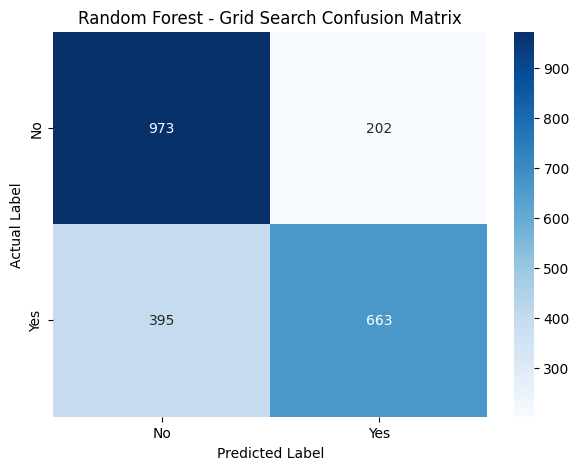

In [9]:

cm_grid = confusion_matrix(y_test, y_pred_grid)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_grid,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['No', 'Yes'],
    yticklabels=['No', 'Yes']
)

plt.title("Random Forest - Grid Search Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.show()


In [10]:

output_dir = "/kaggle/working/grid_search_results"
os.makedirs(output_dir, exist_ok=True)

grid_results = pd.DataFrame({
    'Model': ['Random Forest Grid Search'],
    'Accuracy': [grid_accuracy],
    'Precision': [grid_precision],
    'Recall': [grid_recall],
    'F1-Score': [grid_f1],
    'Search Time': [grid_search_time],
    'Prediction Time': [grid_prediction_time],
    'Best CV F1': [grid_search.best_score_]
})

grid_results.to_csv(
    f"{output_dir}/grid_search_metrics.csv",
    index=False
)

pd.DataFrame([grid_search.best_params_]).to_csv(
    f"{output_dir}/best_parameters.csv",
    index=False
)

pd.DataFrame(cm_grid).to_csv(
    f"{output_dir}/grid_confusion_matrix.csv",
    index=False
)

# Save all cross-validation results
pd.DataFrame(grid_search.cv_results_).to_csv(
    f"{output_dir}/grid_cv_results.csv",
    index=False
)

print("Grid Search results saved successfully!")

display(grid_results)


Grid Search results saved successfully!


,Model,Accuracy,Precision,Recall,F1-Score,Search Time,Prediction Time,Best CV F1
0,Random Forest Grid Search,0.732647,0.766474,0.626654,0.689548,142.529841,0.114934,0.69344
